In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Connect and Access Git Repository

import sys
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())

GitHub token: ··········
Cloning into '/content/bachelor-thesis'...
remote: Enumerating objects: 431, done.
remote: Counting objects: 100% (167/167), done.
remote: Compressing objects: 100% (138/138), done.
remote: Total 431 (delta 90), reused 65 (delta 28), pack-reused 264 (from 1)
Receiving objects: 100% (431/431), 24.90 MiB | 19.03 MiB/s, done.
Resolving deltas: 100% (207/207), done.
/content/bachelor-thesis
Repo exists: True


In [ ]:
# Imports
import os
import numpy as np
import torch
from torch.utils.data import DataLoader


# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))

from utils.dataset import PTBXLTranADDataset
from explainability.attention import TranADExplainability
from utils.seed import set_seed, RANDOM_SEED
from models.tranad import TranADMainModel
from utils.anomaly_threshold import ChooseThresholdForRecall
from explainability.evaluation import plot_temporal_importance

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cpu


In [ ]:
# Paths to Directories

DATA_DIR = Path("/content/drive/MyDrive/ECG data")
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"

MODEL_DIR = RESULTS_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRANAD_MODEL_DIR = MODEL_DIR / "tranad"
TRANAD_MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRANAD_MODEL_PATH = TRANAD_MODEL_DIR / "tranad_20epochs_larger_capacity.pt"

print("MODEL_DIR:", TRANAD_MODEL_DIR)
print("MODEL_PATH:", TRANAD_MODEL_PATH)

MODEL_DIR: /content/drive/MyDrive/ECG data/results/models/tranad
MODEL_PATH: /content/drive/MyDrive/ECG data/results/models/tranad/tranad_20epochs_larger_capacity.pt


In [ ]:
# Load my preprocessed data

X_train = np.load(os.path.join(PROCESSED_DIR, "X_train.npy"))
y_train = np.load(os.path.join(PROCESSED_DIR, "y_train.npy"))

X_val = np.load(os.path.join(PROCESSED_DIR, "X_val.npy"))
y_val = np.load(os.path.join(PROCESSED_DIR, "y_val.npy"))

X_test = np.load(os.path.join(PROCESSED_DIR, "X_test.npy"))
y_test = np.load(os.path.join(PROCESSED_DIR, "y_test.npy"))


print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(17418, 1000, 12) (17418,)
(2183, 1000, 12) (2183,)
(2198, 1000, 12) (2198,)


In [ ]:
# Training only on normal data

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

print("Training on normal ECGs:", X_train_normal.shape)

Training on normal ECGs: (7596, 1000, 12)


In [ ]:
# Datasets

train_dataset = PTBXLTranADDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

val_dataset = PTBXLTranADDataset(
    X_val,
    y_val,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

test_dataset = PTBXLTranADDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [ ]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False
)

In [ ]:
# Check the shapes

# Expected:
#         Batch X: torch.Size([4, 1000, 12])
#         Batch y: torch.Size([4])

batch_x, batch_y = next(iter(train_loader))

print(batch_x.shape)
print(batch_y.shape)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


torch.Size([4, 1000, 12])
torch.Size([4])


In [ ]:
# Create Model

TranAD = TranADMainModel(
    NumFeatures=12,
    ModelDimension=64,
    NumHeads=4,
    NumEncoderLayers=2,
    NumDecoderLayers=2,
    ForwardDimension=128,
    DropoutRate=0.1,
    LearningRate=1e-4,
    FocusGrowthRate=1.05,
    InitialFocusScore=1.0,
    MaxFocusScore=5.0,
    AnomalyPercentile=95.0,
)

TranADModel: 268,376 Parameter | d_model=64, H=4, Enc=2, Dec×2=2


In [ ]:
# Test

batch_x = batch_x.to(TranAD.Device)

x1, x2 = TranAD.Network(batch_x)

print(x1.shape)
print(x2.shape)

torch.Size([4, 1000, 12])
torch.Size([4, 1000, 12])


In [ ]:
# Load saved model instead of retraining

TranAD.Load(str(TRANAD_MODEL_PATH))

Model loaded  /content/drive/MyDrive/ECG data/results/models/tranad/tranad_20epochs_larger_capacity.pt


In [ ]:
# reset the anomay threshold because we have a new calculating technique
TranAD.AnomalyThreshold = None

In [ ]:
# Training

print("\n── TranAD Training starts ─────────────────────────────")

TranAD.TrainModel(
    TrainingLoader = train_loader,
    NumEpochs      = 20,
    PrintInterval  = 1,
)

In [ ]:
# Save the Model after training

print("\n── Saving TranAD model ────────────────────────────────")

TranAD.Save(str(TRANAD_MODEL_PATH))


── Saving TranAD model ────────────────────────────────
Model saved  /content/drive/MyDrive/ECG data/results/models/tranad_20epochs_larger_capacity.pt


In [ ]:
# Calculating scores from validation set

ValidationScores = TranAD.CalculateScores(DataLoaderObject=val_loader)

ValidationLabels = np.asarray(y_val).astype(int).reshape(-1)

print("Validation scores shape:", ValidationScores.shape,)
print("Validation labels shape:", ValidationLabels.shape,)
print("Normal validation records:", (ValidationLabels == 0).sum(),)
print("Anomalous validation records:", (ValidationLabels == 1).sum(),)
print("Mean normal score:", ValidationScores[ValidationLabels == 0].mean(),)
print("Mean anomalous score:", ValidationScores[ValidationLabels == 1].mean(),)

Validation scores shape: (2183,)
Validation labels shape: (2183,)
Normal validation records: 955
Anomalous validation records: 1228
Mean normal score: 0.015654061
Mean anomalous score: 0.11856051


In [ ]:
# choose Threshold based on minimum TargetRecall

ThresholdResult = ChooseThresholdForRecall(
    Labels=ValidationLabels,
    Scores=ValidationScores,
    TargetRecall=0.80,
)

ChosenThreshold = ThresholdResult["Threshold"]

print("Chosen threshold:", ChosenThreshold)
print("Validation precision:", ThresholdResult["Precision"])
print("Validation recall:", ThresholdResult["Recall"])

Chosen threshold: 0.010166172869503498
Validation precision: 0.6132252027448534
Validation recall: 0.8004885993485342


In [ ]:
# Anomaly detection

print("\n── TranAD Anomaly Detection ─────────────────────────────")


AnomalyScores, BinaryPredictions = (
    TranAD.DetectAnomalies(
        TestLoader=test_loader,
        Threshold=ChosenThreshold,
    )
)


print("Test scores shape:", AnomalyScores.shape)
print("Test predictions shape:", BinaryPredictions.shape)
print("Detected anomalous records:", BinaryPredictions.sum())
print("Validation-derived threshold:", TranAD.AnomalyThreshold)


── TranAD Anomaly Detection ─────────────────────────────
Test scores shape: (2198,)
Test predictions shape: (2198,)
Detected anomalous records: 1626
Validation-derived threshold: 0.010166172869503498


In [ ]:
# Evaluation

print("\n── TranAD Evaluation ───────────────────────────")


TestLabels = np.asarray(y_test).astype(int).reshape(-1)

Metrics = TranAD.Evaluate(
    TrueLabels=TestLabels,
    Scores=AnomalyScores,
    PredictedLabels=BinaryPredictions,
)


── TranAD Evaluation ───────────────────────────

TranAD Evaluation Results ──────────────────
  Accuracy            : 0.6065
  Precision           : 0.6138
  Recall              : 0.8081
  F1Score             : 0.6977
  FalseNegativeRate   : 0.1919
  Threshold           : 0.010166
  TruePositive        : 998
  TrueNegative        : 335
  FalsePositive       : 628
  FalseNegative       : 237
  ROC_AUC             : 0.6695
  PR_AUC              : 0.7348
  ConfusionMatrix
    : [[335 628]
 [237 998]]


In [ ]:
# Save TranAD test outputs for shared sample selection


from pathlib import Path
import numpy as np

EVALUATION_DIR = RESULTS_DIR / "evaluation"
EVALUATION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TranADOutputPath = (
    EVALUATION_DIR
    / "tranad_test_outputs.npz"
)

np.savez_compressed(
    TranADOutputPath,

    scores=np.asarray(
        AnomalyScores,
        dtype=np.float32,
    ),

    predictions=np.asarray(
        BinaryPredictions,
        dtype=np.int64,
    ),

    labels=np.asarray(
        TestLabels,
        dtype=np.int64,
    ),

    threshold=np.asarray(
        ChosenThreshold,
        dtype=np.float32,
    ),
)

print(
    "Saved TranAD test outputs to:",
    TranADOutputPath,
)

Saved TranAD test outputs to: /content/drive/MyDrive/ECG data/results/evaluation/tranad_test_outputs.npz


In [ ]:
SharedSamples = np.load(
    RESULTS_DIR
    / "evaluation"
    / "shared_explanation_samples.npz"
)

NormalIndex = int(
    SharedSamples["normal_index"]
)

AnomalousIndex = int(
    SharedSamples["anomalous_index"]
)


NormalECG, NormalLabel = test_dataset[NormalIndex]
AnomalousECG, AnomalousLabel = test_dataset[AnomalousIndex]

NormalECG = NormalECG.unsqueeze(0).to(TranAD.Device)
AnomalousECG = AnomalousECG.unsqueeze(0).to(TranAD.Device)

print("Index of Normal ECG:", NormalIndex, "Label:", NormalLabel.item())
print("Index of Anomalous ECG:", AnomalousIndex, "Label:", AnomalousLabel.item())

Index of Normal ECG: 583 Label: 0
Index of Anomalous ECG: 495 Label: 1



── TranAD Attention-based Explainability ─────────────────────


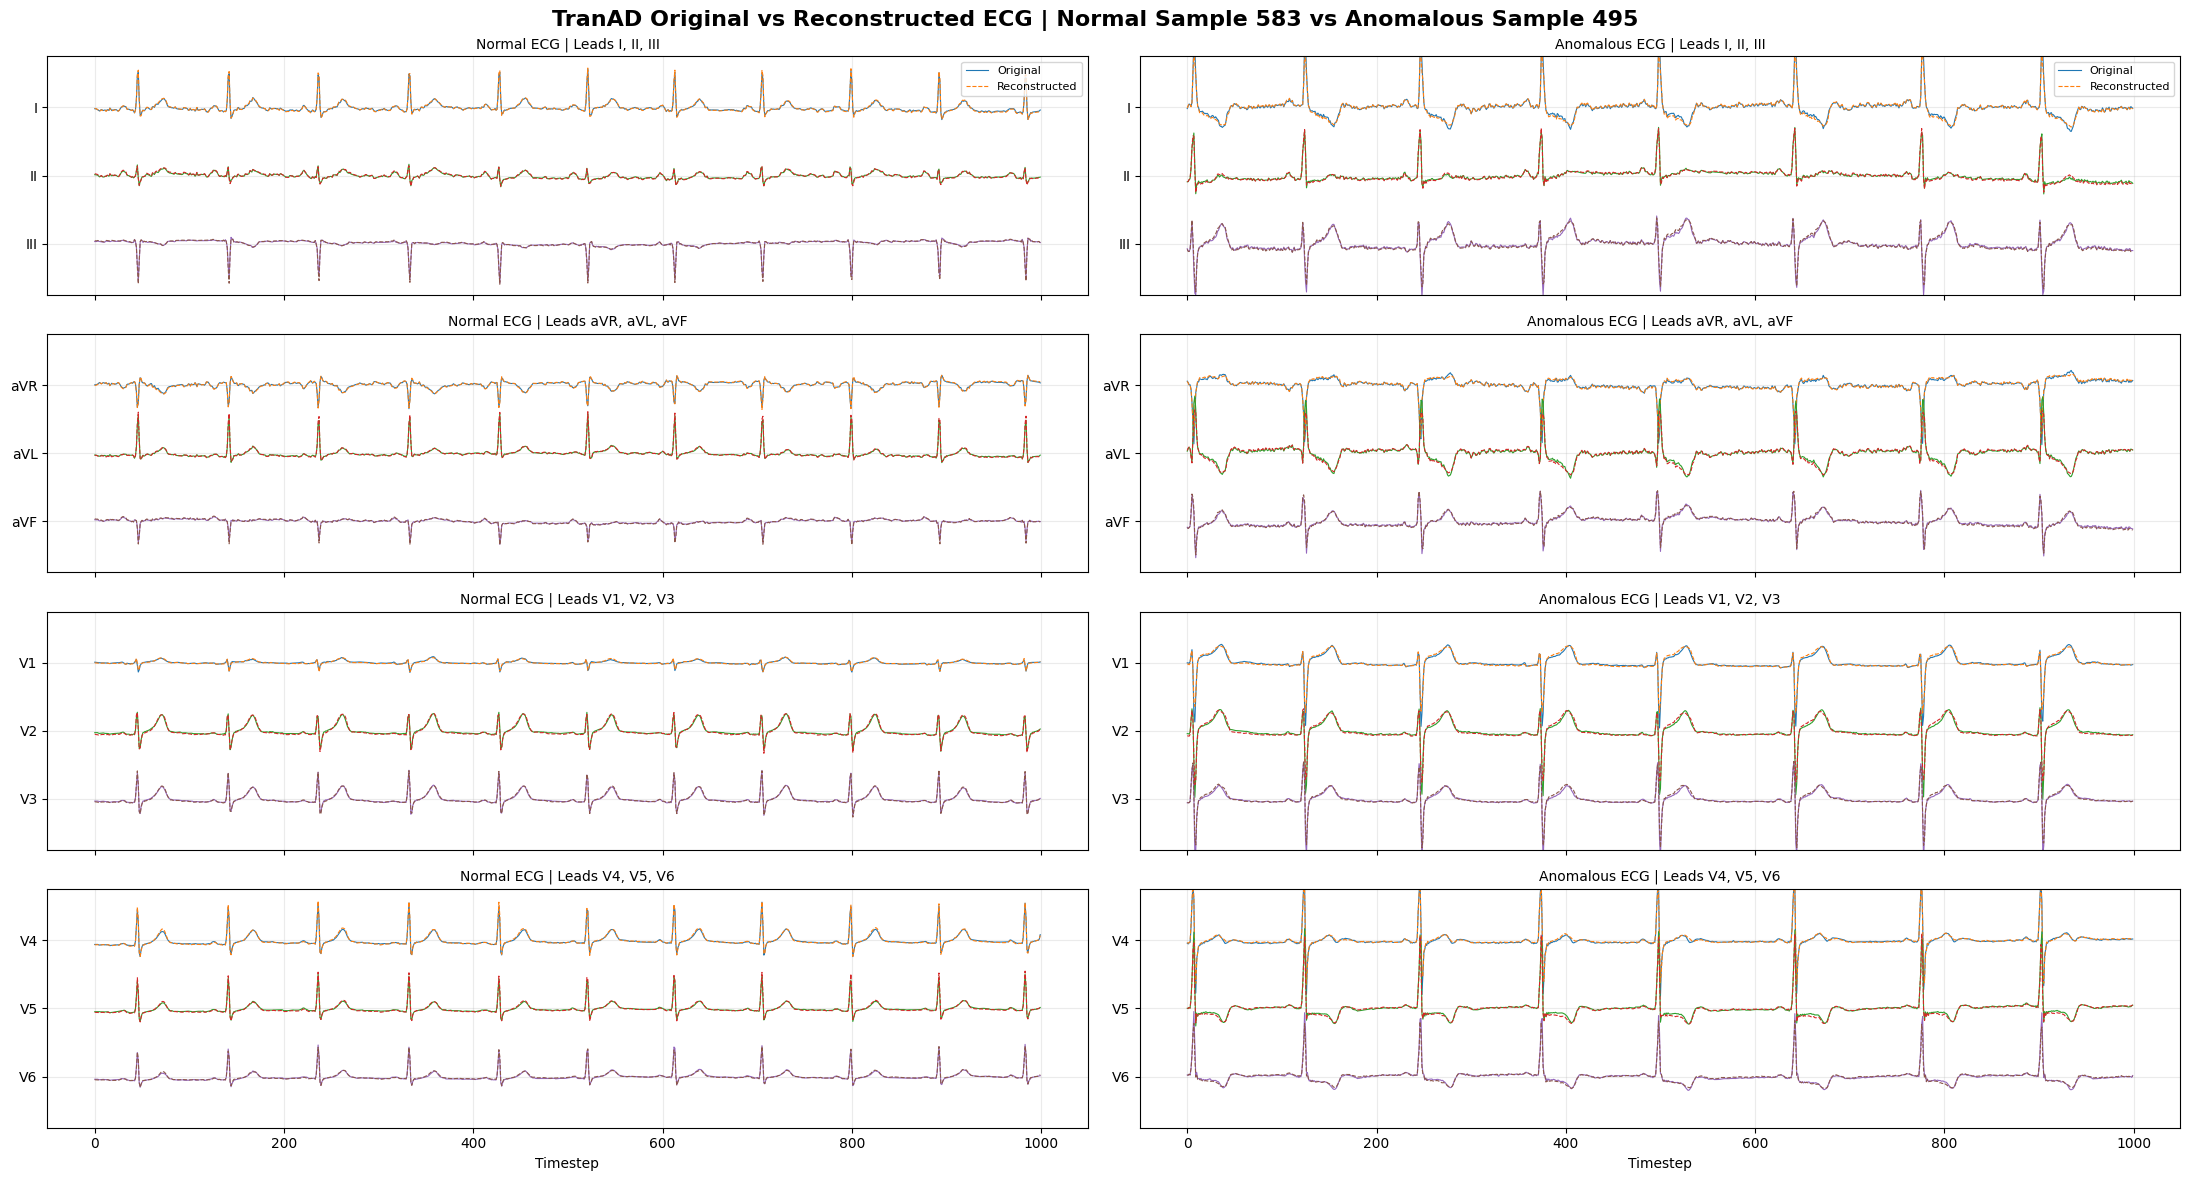

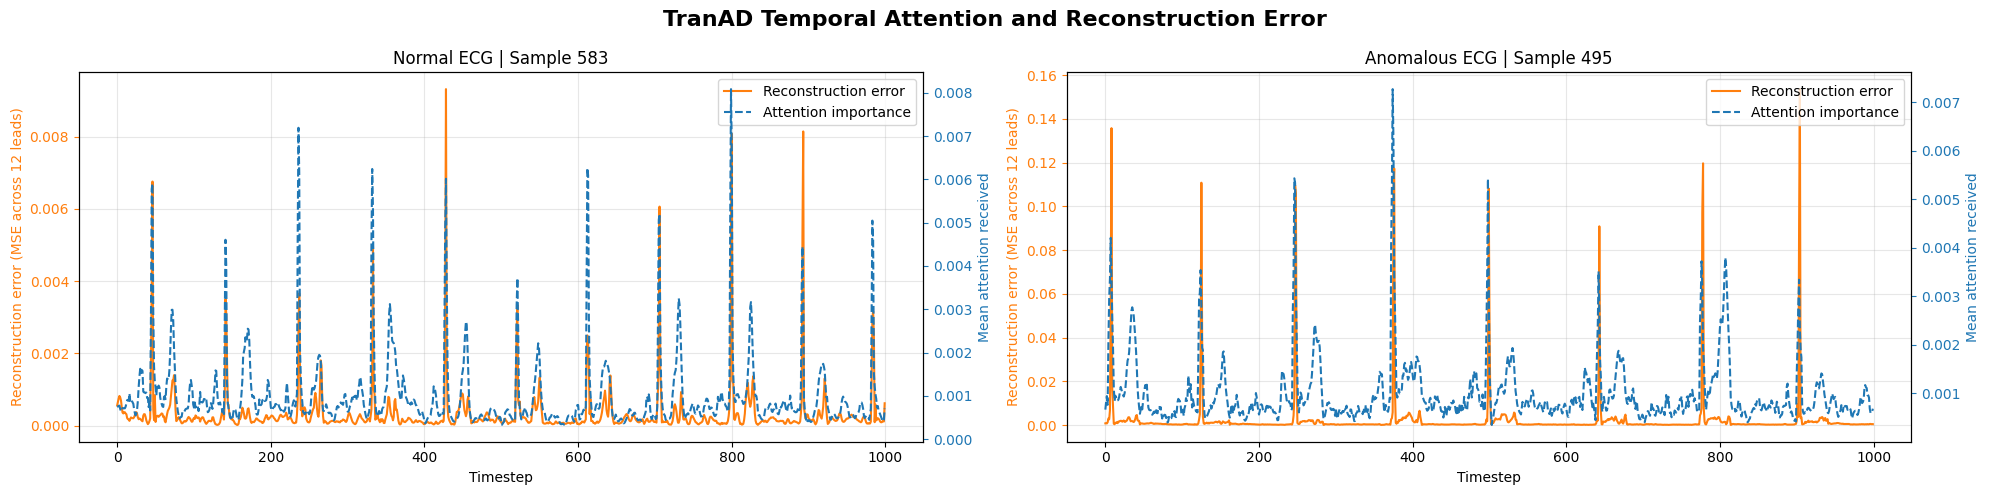

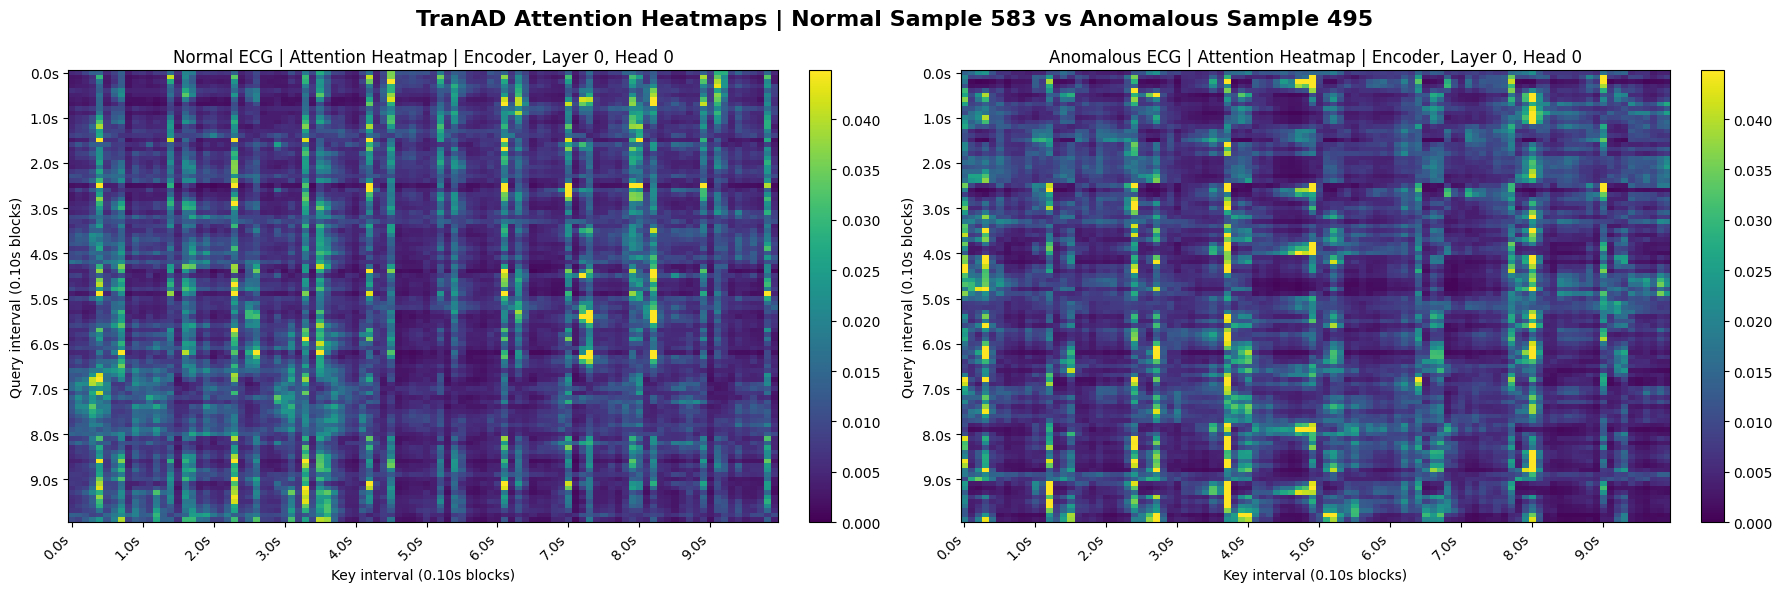

In [ ]:
# TranAD Attention-based Explainability


print("\n── TranAD Attention-based Explainability ─────────────────────")

Explainer = TranADExplainability(TranAD)


Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    Component="Encoder",
    LayerIndex=0,
    HeadIndex=0,
    Percentile=99.0,
    UseIntervalHeatmap=True,
    BlockSize=10,
    Aggregation="mean_attention_mass",
    SamplingRate=100,
)

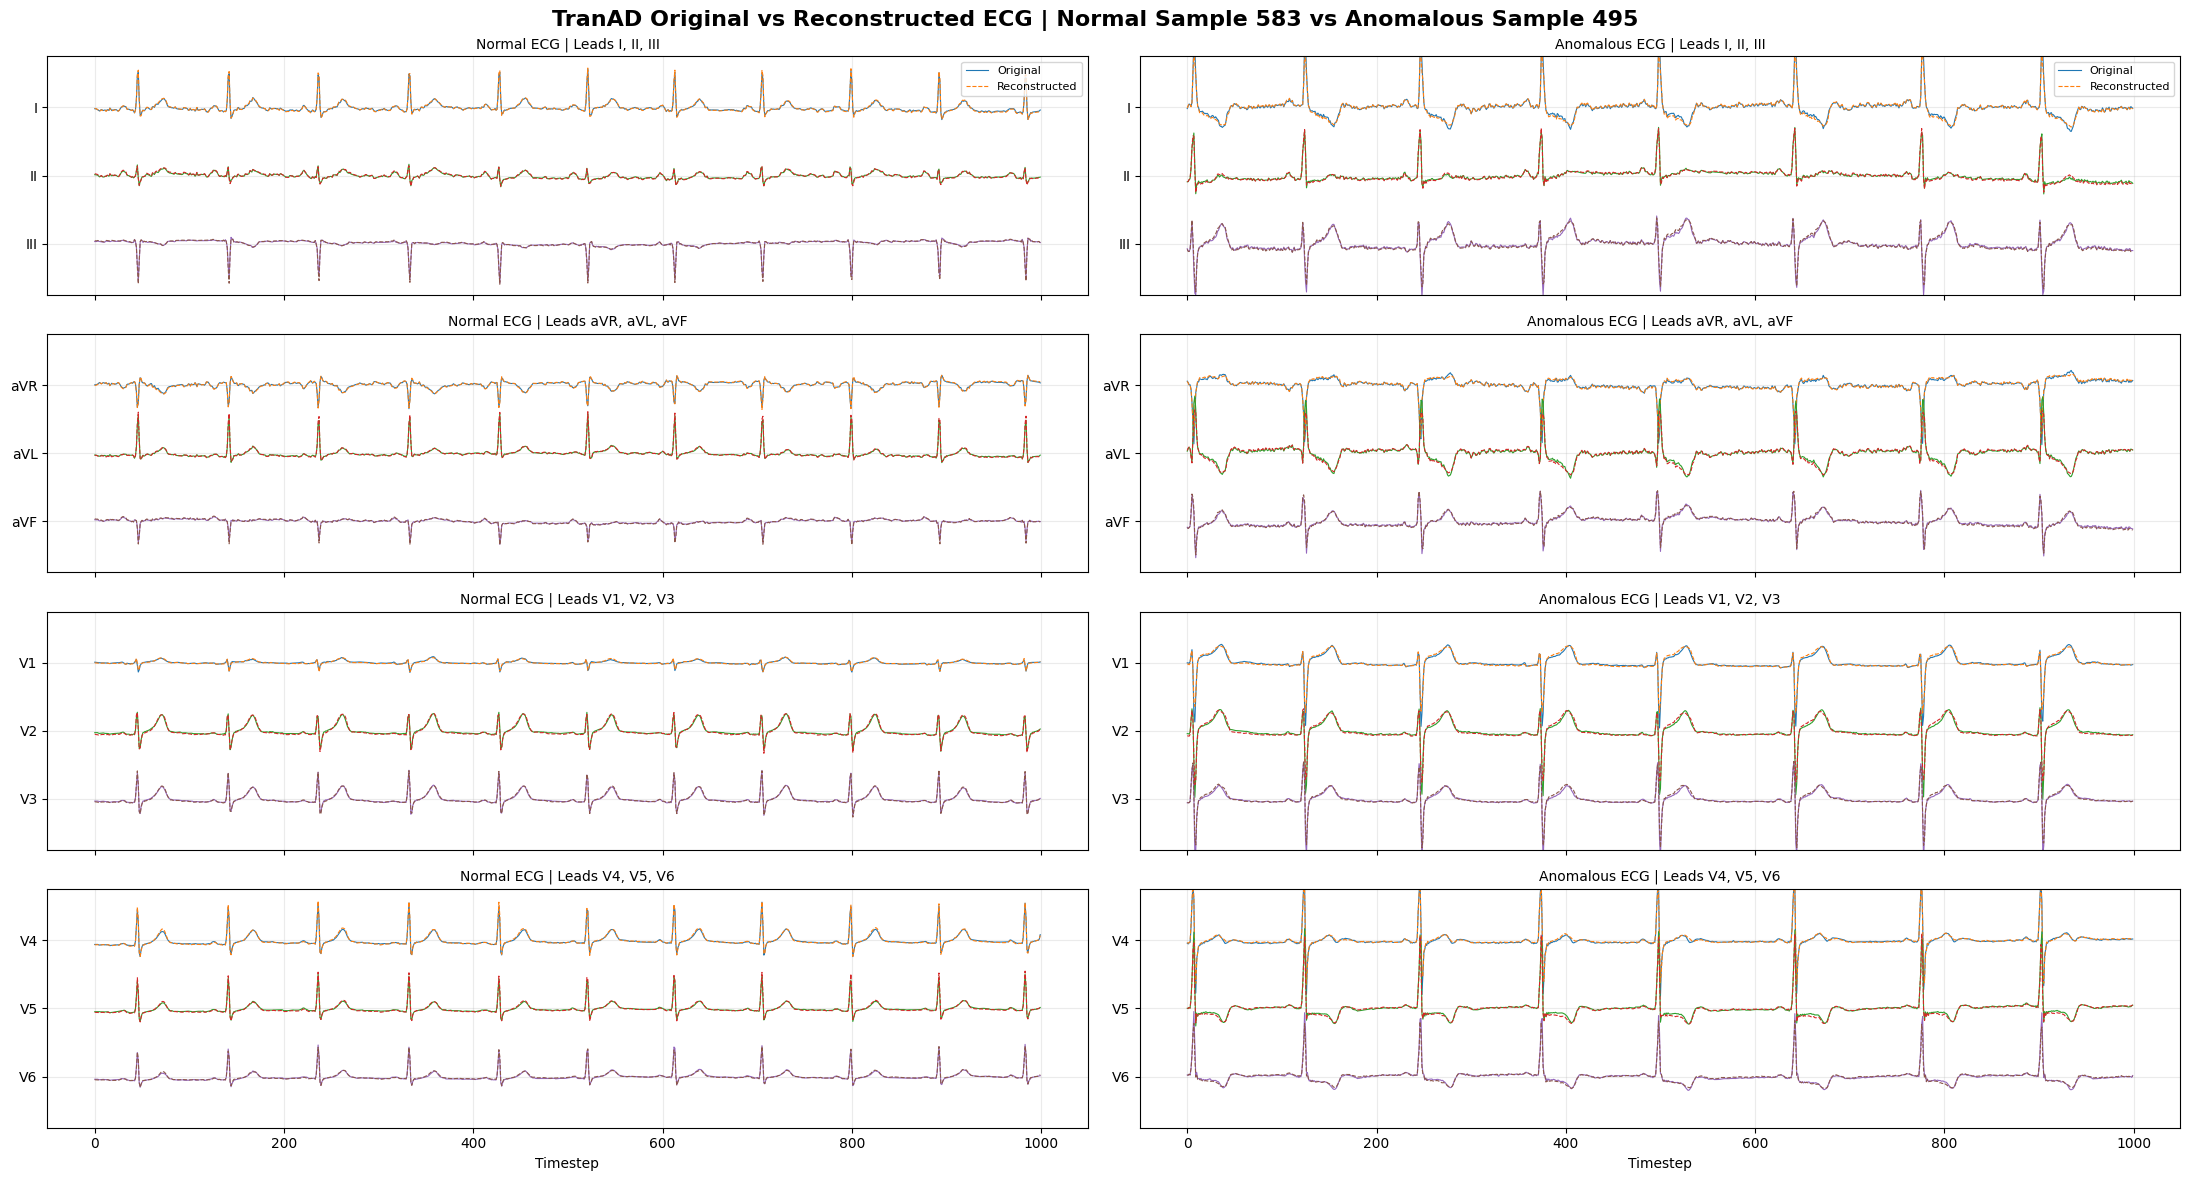

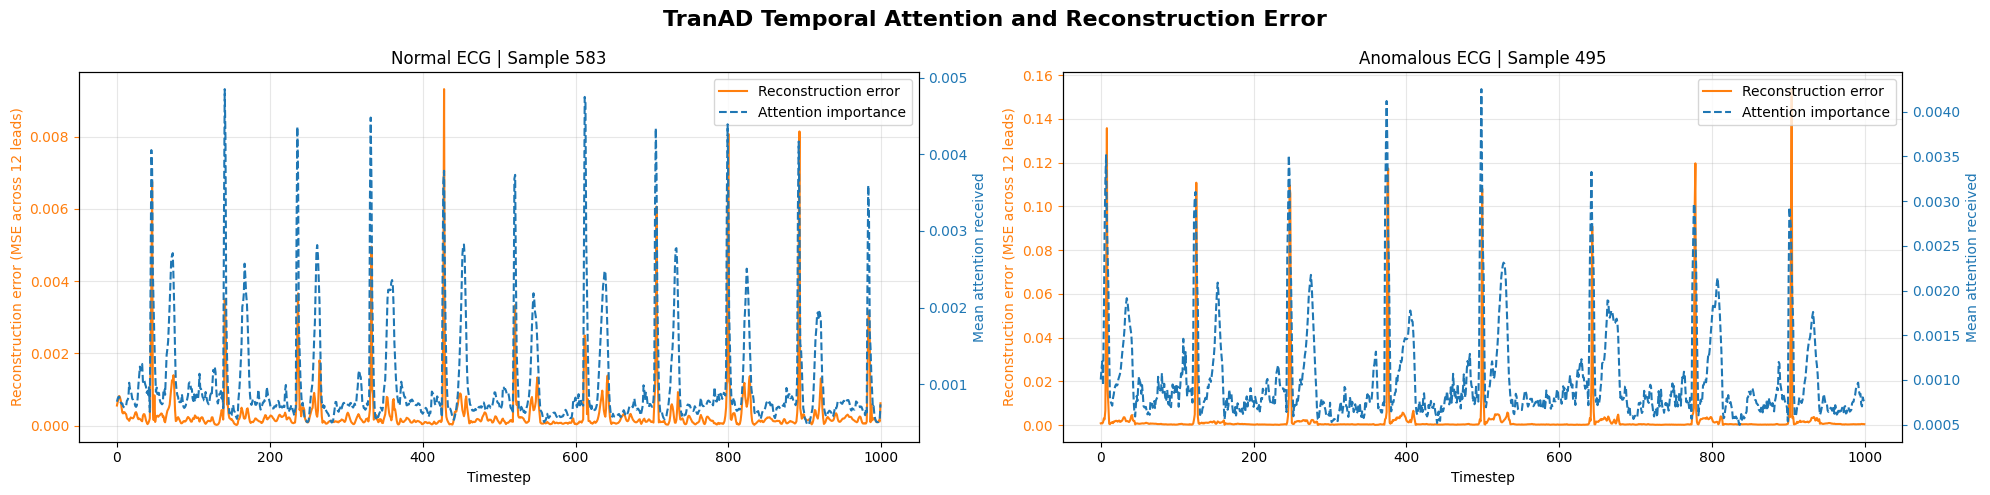

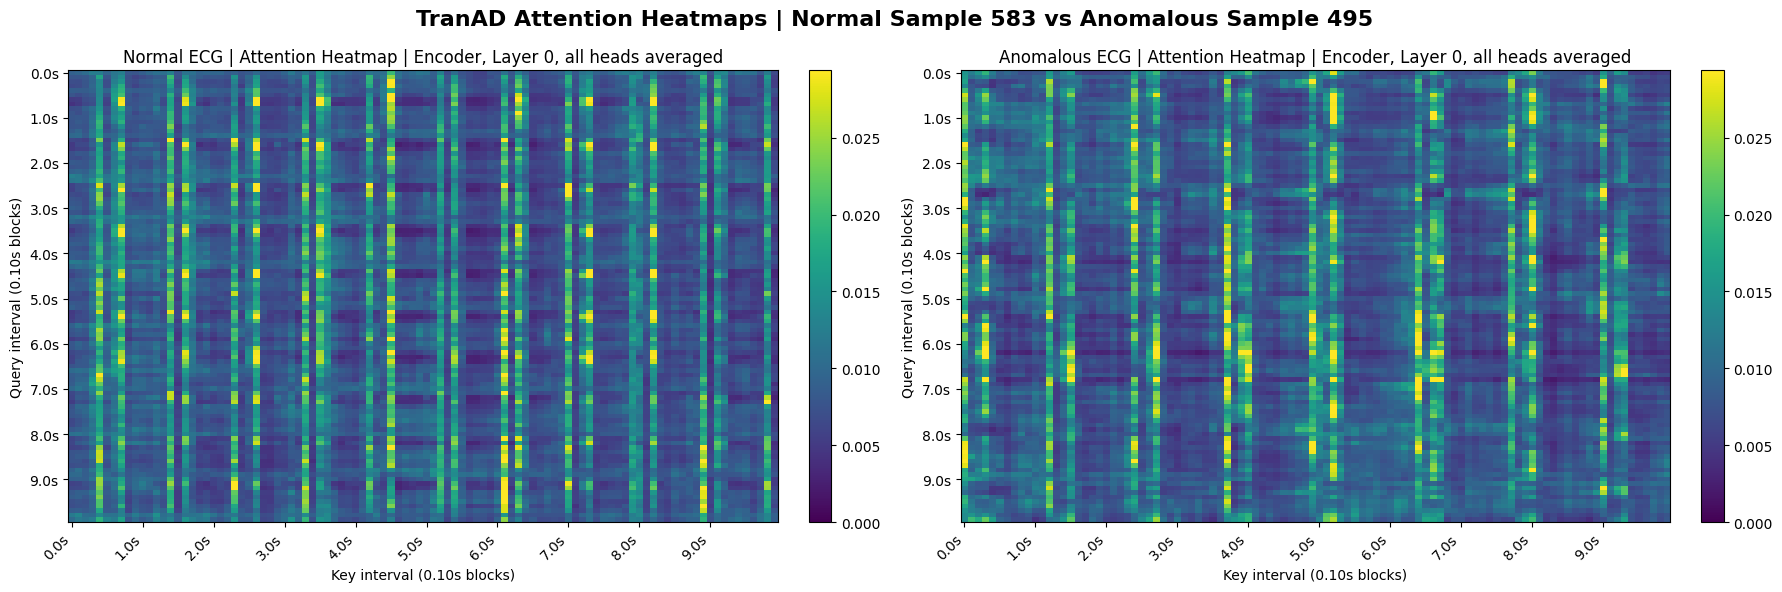

In [ ]:
Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    Component="Encoder",
    LayerIndex=0,
    HeadIndex=None,       # all heads averaged
    Percentile=99.0,
)

In [ ]:
NormalTemporalAttention = (
    TranADExplainer.GetIntervalAttentionImportance(
        TimeSeriesWindow=NormalECG,
        Component="Encoder",
        LayerIndex=0,
        HeadIndex=None,
        BlockSize=10,
    )
)

AnomalousTemporalAttention = (
    TranADExplainer.GetIntervalAttentionImportance(
        TimeSeriesWindow=AnomalousECG,
        Component="Encoder",
        LayerIndex=0,
        HeadIndex=None,
        BlockSize=10,
    )
)

print("Normal:", NormalTemporalAttention.shape)
print("Anomalous:", AnomalousTemporalAttention.shape)

In [ ]:
plot_temporal_importance(
    values=NormalTemporalAttention,
    title="TranAD attention importance — normal ECG",
    save_path=(
        RESULTS_DIR
        / "evaluation"
        / "tranad_temporal_attention_normal.png"
    ),
)

plot_temporal_importance(
    values=AnomalousTemporalAttention,
    title="TranAD attention importance — anomalous ECG",
    save_path=(
        RESULTS_DIR
        / "evaluation"
        / "tranad_temporal_attention_anomalous.png"
    ),
)

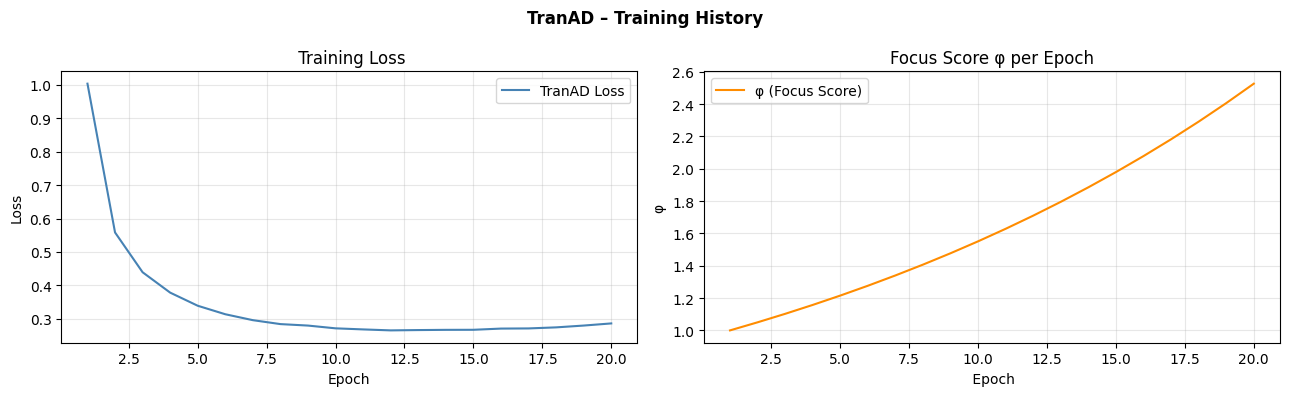

In [ ]:
# Show training loss

Explainer.ShowTrainingHistory()